# 01 - Exploratory data analysis

Author: Pedro Leite 106812 

Conclusions from the analysis: 
1. The values of the output have big outliers, which will affect the quality of the fit, since the cost is quadratic. In order to solve this, we should to a non-linear transformation. One transformation that was discussed is the log transformation; Clipping is also a good solution in order to not affect when an output becomes a lag;
2. Autocorrelation between the outputs for diferent lags using PACF and ACF were done, which revealed a seasonal factor (expected). By fitting a seasonal model, and computing the residuals with it, we can see how the real distribution of outputs behaves. The graphs revelead that the system composed of only lags of the outputs (AR) that the most appropriate value is 1 lag.
3. In order to understand which features are the most important for the output, a correlation matrix was created between the residuals and the exogeneous variables. The most important features are: nitrate, upwelling, wind, current, mixture. Ranges for the number of lags for each feature were determined, based on the gain, on the season independent case. 


In [1]:
import sys  
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# This notebook lives in submission/training_code/notebooks/.
SUBMISSION = Path.cwd().resolve().parents[1]
PROJECT_ROOT = SUBMISSION.parent
DATA = PROJECT_ROOT / "data" / "chlorophyll_student_2015_2023.csv"  # not shipped in the submission

# Shared feature code: the same implementation the final model uses.
sys.path.insert(0, str(SUBMISSION / "best_model"))
import utils
 
DATE, TARGET = utils.DATE, utils.TARGET

In [2]:
raw = pd.read_csv(DATA)
raw[DATE] = pd.to_datetime(raw[DATE])
raw = raw.sort_values(DATE).reset_index(drop=True)
raw 

,date,chlorophyll_a_mg_m3,sst_c,par_umol_m2_s,nitrate_umol_l,wind_speed_m_s,upwelling_index,mixed_layer_depth_m,salinity_psu,current_speed_m_s,river_discharge_index,cloud_fraction,surface_pressure_hpa,turbidity_ntu
0,2015-01-01,1.384479,11.481587,149.109963,6.015581,6.312241,0.888380,31.398514,35.267326,0.243345,1.454131,0.772424,1013.630651,2.712575
1,2015-01-02,1.163834,11.645005,102.709144,5.378356,6.419118,0.069684,32.582147,35.232201,0.305887,1.504132,0.720854,1013.746950,2.929409
2,2015-01-03,1.159372,11.306775,113.837502,6.347327,7.360378,1.600903,34.065341,35.221364,0.363735,1.290741,0.734412,1014.856950,2.631379
3,2015-01-04,1.370594,12.116982,173.914824,6.120668,7.730971,1.282715,34.538421,35.267070,0.402836,1.644759,0.642274,1013.131768,2.668686
4,2015-01-05,1.637080,11.822242,76.814006,5.257523,6.902393,0.519057,35.724733,35.329770,0.364641,1.234290,0.744293,1014.762930,2.520198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3282,2023-12-27,1.621570,11.088536,143.452458,6.498228,6.577302,0.950060,31.684953,35.212846,0.299073,1.481595,0.672182,1016.137173,2.710115
3283,2023-12-28,2.229616,11.704183,116.912919,4.548839,5.338993,-0.524787,30.367574,35.295276,0.284018,1.441067,0.749665,1013.004822,2.927532
3284,2023-12-29,2.488156,11.726448,131.644259,4.821929,5.472798,-0.073166,28.304070,35.409213,0.302164,1.115368,0.643591,1011.011499,2.303944
3285,2023-12-30,2.179340,11.978954,106.974513,4.824874,5.637569,-0.417960,30.626288,35.264886,0.199276,1.609597,0.768992,1014.869372,2.616847


## 1. Overview and data quality

Shape, dtypes, date coverage and gaps, missing values, basic statistics.

In [3]:
# Structure
print(raw.shape); print(raw.dtypes)

# Dates
full = pd.date_range(raw[DATE].min(), raw[DATE].max(), freq="D")
print("missing days:", len(full.difference(raw[DATE])), "| duplicates:", raw[DATE].duplicated().sum())
print(raw.groupby(raw[DATE].dt.year).size())

# Missing values and basic statistics
print(raw.isna().sum().sum())
num = raw.drop(columns=DATE)
print(num.describe().T.assign(skew=num.skew(), kurt=num.kurt()).round(3))


(3287, 14)
date                     datetime64[ns]
chlorophyll_a_mg_m3             float64
sst_c                           float64
par_umol_m2_s                   float64
nitrate_umol_l                  float64
wind_speed_m_s                  float64
upwelling_index                 float64
mixed_layer_depth_m             float64
salinity_psu                    float64
current_speed_m_s               float64
river_discharge_index           float64
cloud_fraction                  float64
surface_pressure_hpa            float64
turbidity_ntu                   float64
dtype: object
missing days: 0 | duplicates: 0
date
2015    365
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
dtype: int64
0
                        count      mean      std       min       25%  \
chlorophyll_a_mg_m3    3287.0     1.747    0.634     0.277     1.312   
sst_c                  3287.0    15.303    3.266     9.228    12.121   
par_umol_m2_s          3287.0   310.625

### Conclusions: 

The chlorophyll shows: 
1. Skew > 0 (the distribution has a big right tale);
2. Kurt > 0 (weight of the tales), very big in this case;
3. LS does not require the variables to be normal, but the outliers will make the penalization on the cost very big;


It's important to count the number of outliers; 

## 2. Target distribution and outliers
Distribution of chlorophyll-a, extreme values, how many and where; candidate winsorization limits and log scale. 

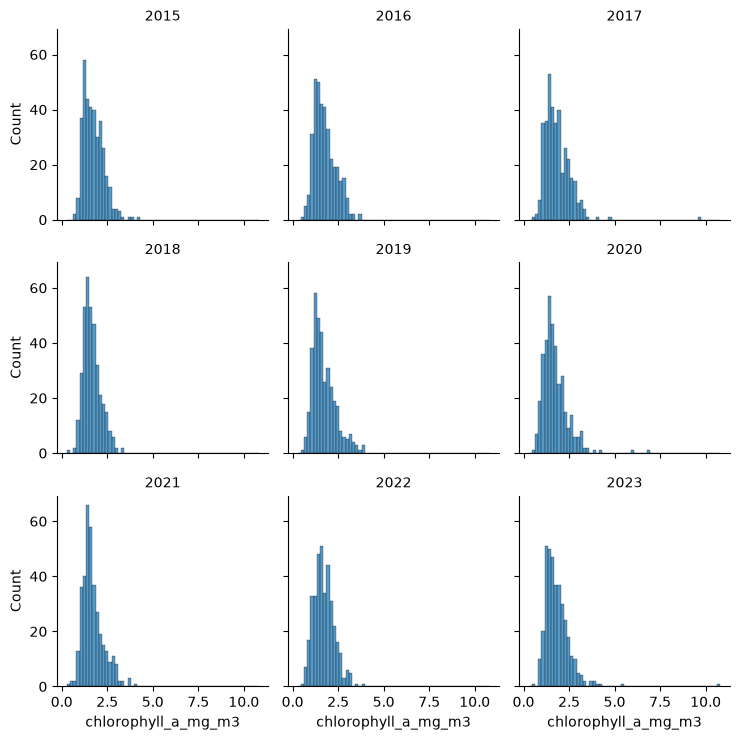

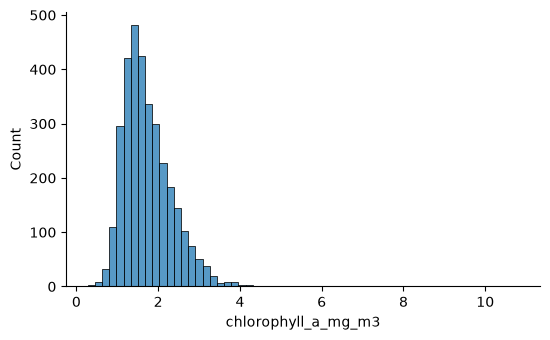

In [4]:
import seaborn as sns

raw["year"] = raw[DATE].dt.year

g = sns.displot(raw, x=TARGET, col="year", col_wrap=3, bins=60, height=2.5)
g.set_titles("{col_name}")

sns.displot(raw, x=TARGET, bins=60, height=3.5, aspect=1.6) 

## Log scale 

One option to deal with these right tails, is to used a log transformation [reference].  And then to convert to the original scale we use the exponencial. There is slight problem which is the fact that it tends to estimate the median and not the mean, this behaviour can be corrected with the use of factor c. 

Normalization is not an option, it's a linear transformation, does not eliminate outliers 

Reference: 
"Hyndman & Athanasopoulos, Forecasting: Principles and Practice (3.ª ed.), secção 3.1 "Mathematical transformations":
 "If the data shows variation that increases or decreases with the level of the series, then a transformation can be useful. For example, a logarithmic transformation is often useful."


## Clipping 
When training the model, if the lag is big it will affect future outputs. This is important, doing some clipping on the value before it goes to the estimator may be a good option. The percentils are defined as hyperparameters to the model. 

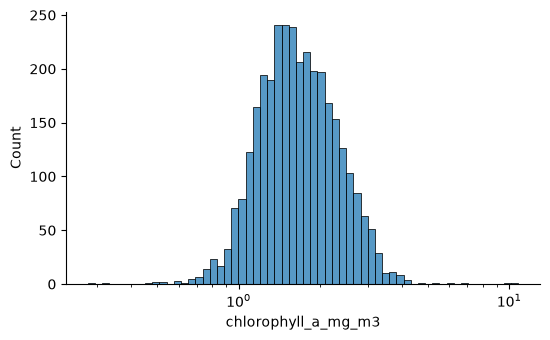

In [5]:
sns.displot(raw, x=TARGET, bins=60, log_scale=True, height=3.5, aspect=1.6)

In [6]:
# Verify on the target when the z score (how many standart deviations is above the mean) of clorophile 
z = (raw[TARGET] - raw[TARGET].mean()) / raw[TARGET].std() #z score 
print(raw.loc[z.abs() > 4, [DATE, TARGET]].assign(z=z.round(1)))  

           date  chlorophyll_a_mg_m3     z
340  2015-12-07             4.303953   4.0
1069 2017-12-05             9.630213  12.4
1094 2017-12-30             4.783312   4.8
2100 2020-10-01             6.926634   8.2
2162 2020-12-02             6.071011   6.8
3198 2023-10-04             5.489572   5.9
3229 2023-11-04            10.811834  14.3


## Outliers: 

They are bad for two reasons: 
1. Distorts the fit when it appears as the target in training;
2. When it appears as a lag feature, it contaminates the prediction of the following day, which returns to normal; 

## 3. Autocorrelation

ACF/PACF of chlorophyll-a to guide the number of target lags p. 


### Resources: 
https://www.youtube.com/watch?v=R-oWTWdS1Jg 


### Notes: 
1. For ACF and PACF, the band corresponds to the 95% confidence for when the autocorrelation is 0. 
2. The autocorrelation of the series with itself is 1


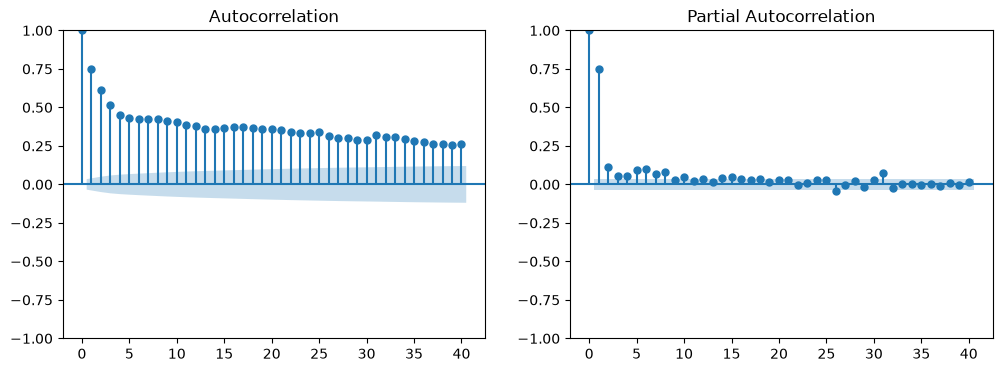

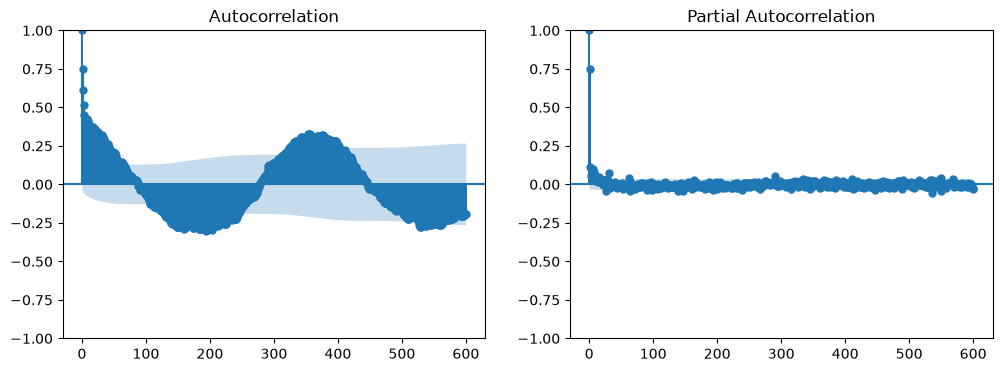

In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf 

fig, axes = plt.subplots(1,2, figsize = (12,4))
plot_acf(raw[TARGET], lags = 40, ax = axes[0])
plot_pacf(raw[TARGET], lags = 40, ax = axes[1])
plt.show()


fig, axes = plt.subplots(1,2, figsize = (12,4))
plot_acf(raw[TARGET], lags = 600, ax = axes[0])
plot_pacf(raw[TARGET], lags = 600, ax = axes[1])
plt.show() 


### Conclusions: 
1. Looking at the PACF, the value of p should not be very high i.e. the lags after 1 do not bring a lot of new information;
2. The series of clorophile values looks like it's an AR(1) process;
3. Looking at the ACF up to 600 lags, we can see that, for lags in the dimensions of a year ~365, the correlation rises again to a maximum, this is because of sazonality. Basically, by comparing y(t) and y(t-365), the two correlate heavly. Looking at lags of half a year, today correlates negatively with the period half a year ago;  
4. By looking at the PACF up to 600 lags, we can see that there is no specific impact of something that happened 365 days ago, so lags at that point in time are not important. The results on ACF where purely season related, there is no extra dependence;  
5. In order to analyze if the seasonality is a factor, lets create compute the residuals between the series and the a seasonal fit to the series;

### How to fit a seasonal timeseries 
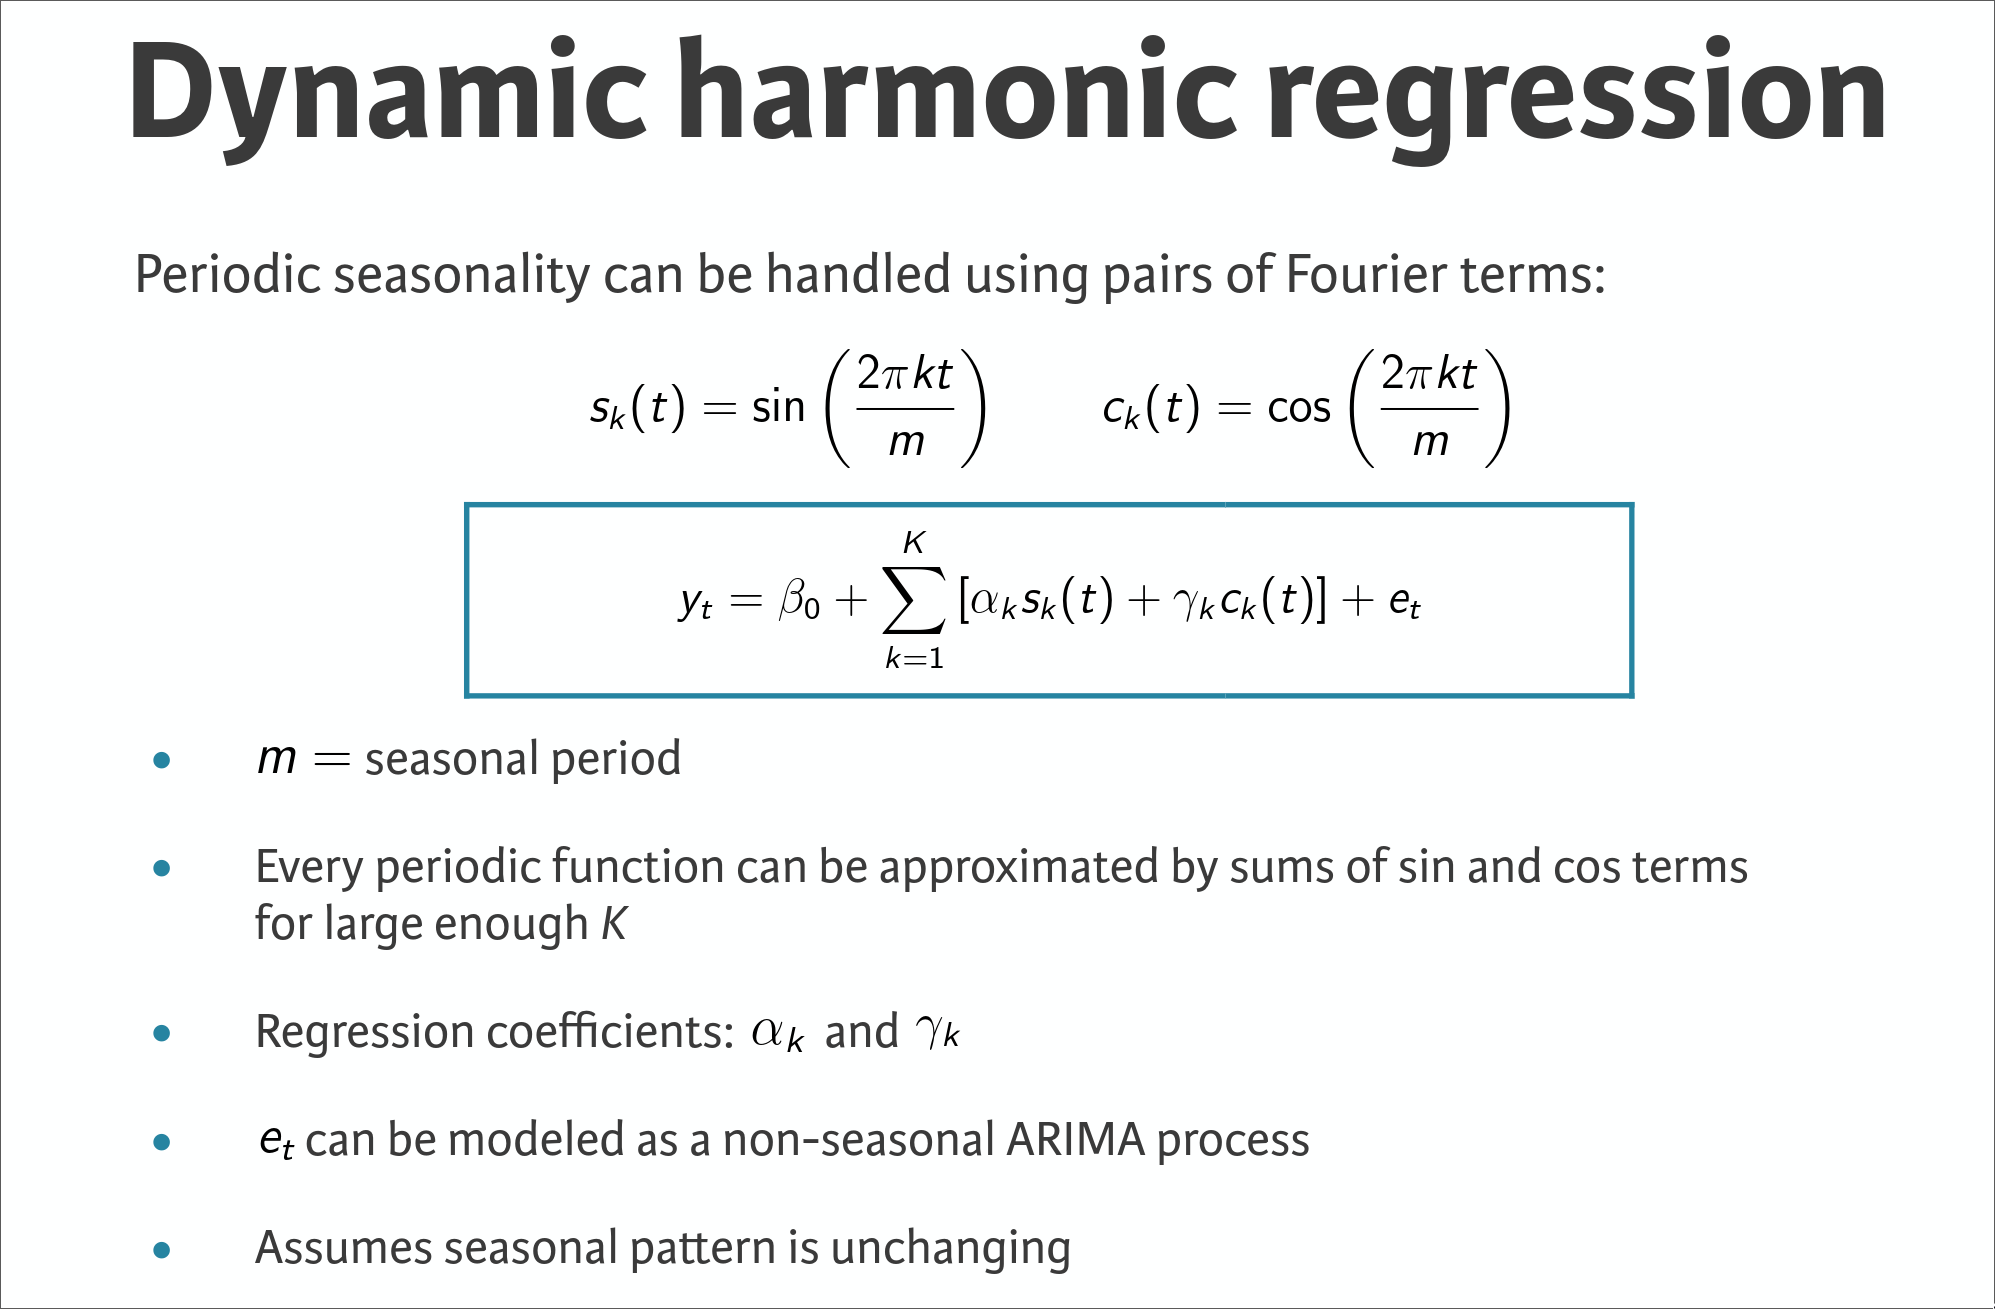


n_harmonics=1: variance explained = 0.339
n_harmonics=2: variance explained = 0.366
n_harmonics=3: variance explained = 0.368
n_harmonics=4: variance explained = 0.370


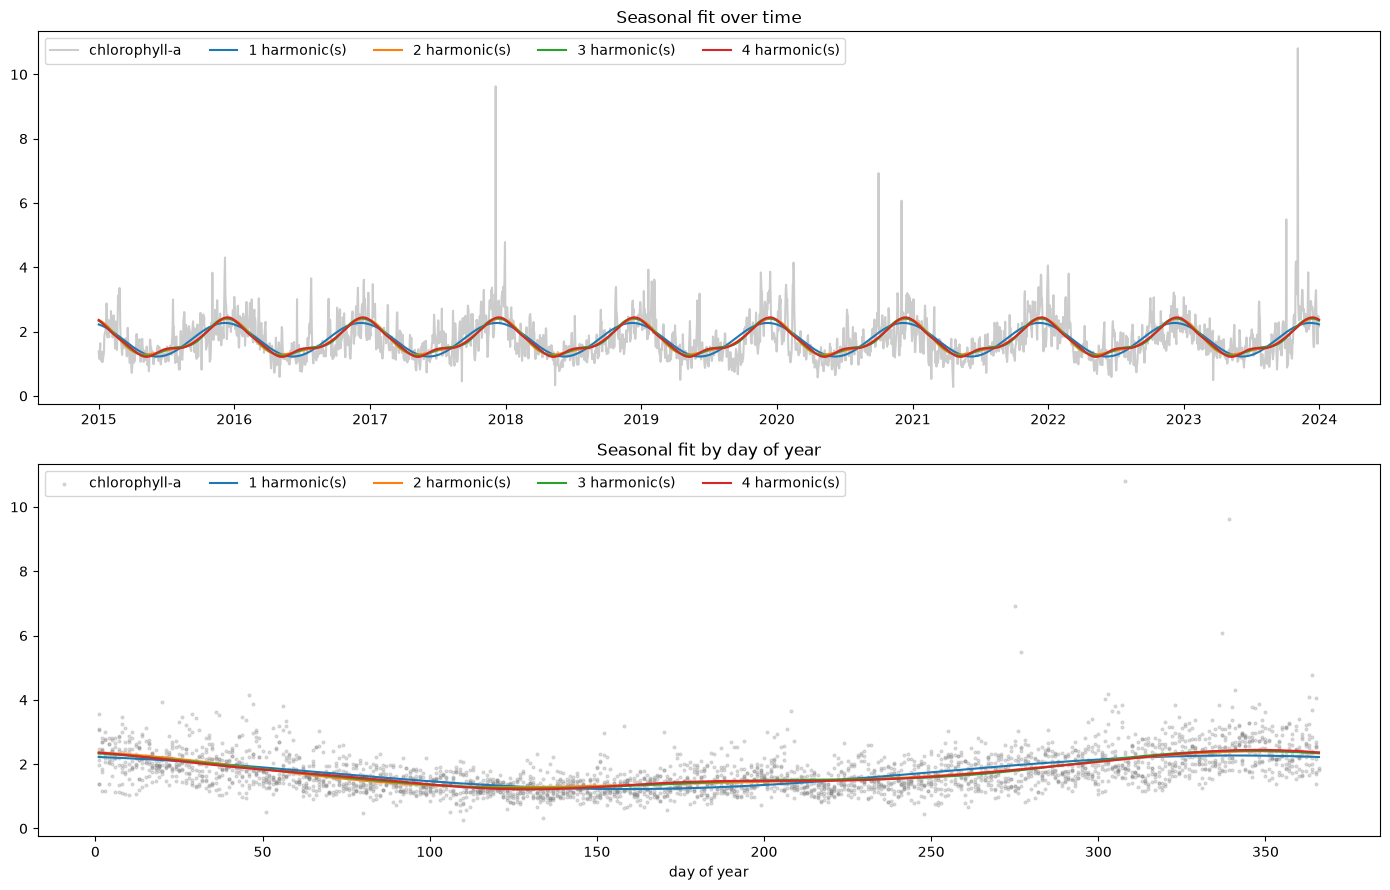

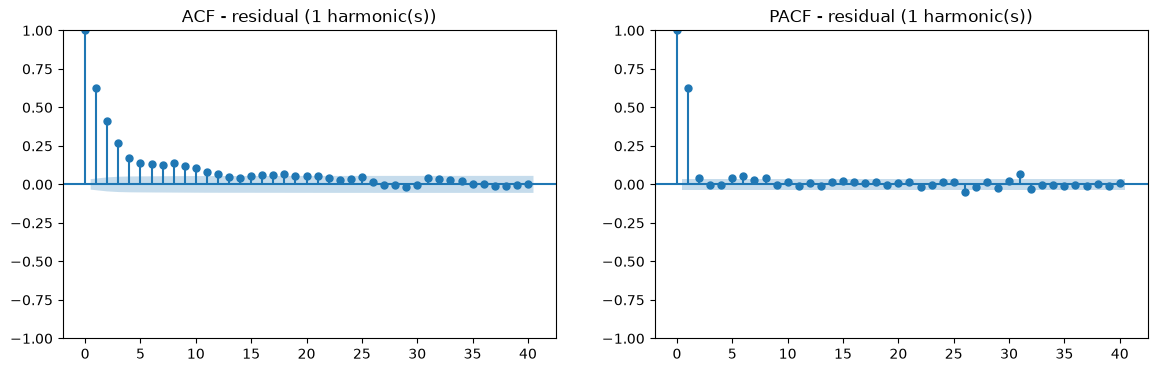

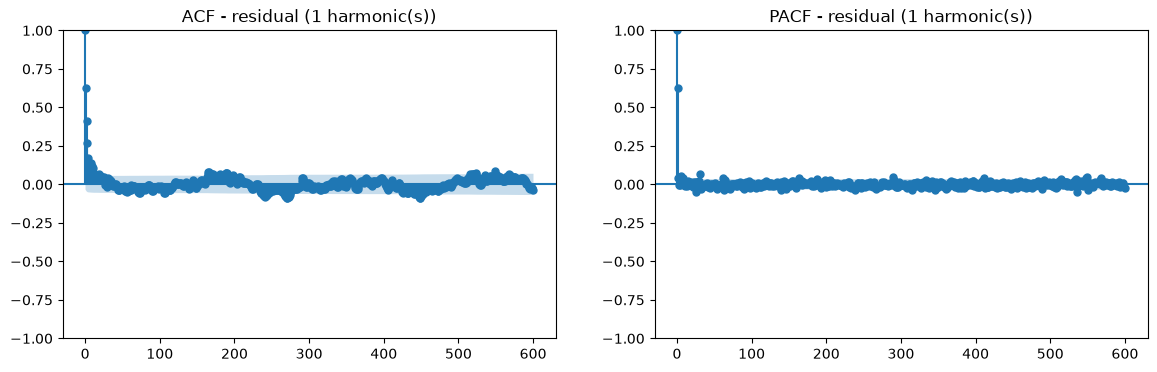

In [17]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

PERIOD = 365.25


def harmonic_design(day_of_year, n_harmonics, period=PERIOD):
    """Design matrix [1, sin_1, cos_1, ..., sin_n, cos_n] from day-of-year values."""
    cols = [np.ones(len(day_of_year))]
    for k in range(1, n_harmonics + 1):
        angle = 2 * np.pi * k * day_of_year / period
        cols += [np.sin(angle), np.cos(angle)]
    return np.column_stack(cols)


def fit_seasonal(raw, n_harmonics):
    """Least-squares fit of the target to an annual cycle.

    Returns (fitted, residual, coefficients).
    """
    y = raw[TARGET].to_numpy()
    day = raw[DATE].dt.dayofyear.to_numpy()
    Z = harmonic_design(day, n_harmonics)
    coef, *_ = np.linalg.lstsq(Z, y, rcond=None)
    fitted = Z @ coef
    return fitted, y - fitted, coef


y = raw[TARGET].to_numpy()
MAX_HARMONICS = 4

fits = {n: fit_seasonal(raw, n) for n in range(1, MAX_HARMONICS + 1)}
for n, (_, r, _) in fits.items():
    print(f"n_harmonics={n}: variance explained = {1 - r.var() / y.var():.3f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(raw[DATE], y, color="gray", alpha=0.4, label="chlorophyll-a")
for n, (fitted, _, _) in fits.items():
    axes[0].plot(raw[DATE], fitted, label=f"{n} harmonic(s)")
axes[0].set_title("Seasonal fit over time")
axes[0].legend(ncol=5)

day_obs = raw[DATE].dt.dayofyear.to_numpy()
days = np.arange(1, 367)
axes[1].scatter(day_obs, y, s=4, color="gray", alpha=0.25, label="chlorophyll-a")
for n, (_, _, coef) in fits.items():
    axes[1].plot(days, harmonic_design(days, n) @ coef, label=f"{n} harmonic(s)")
axes[1].set_xlabel("day of year")
axes[1].set_title("Seasonal fit by day of year")
axes[1].legend(ncol=5)

plt.tight_layout()
plt.show()

N_HARMONICS = 1
_, resid, _ = fits[N_HARMONICS]

for nlags in (40, 600):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(resid, lags=nlags, ax=axes[0], title=f"ACF - residual ({N_HARMONICS} harmonic(s))")
    plot_pacf(resid, lags=nlags, ax=axes[1], title=f"PACF - residual ({N_HARMONICS} harmonic(s))")
    plt.show()

### Conclusions: 

1. Taking the season factor off, we can see that the structure of clorofile is close a AR(1), process:
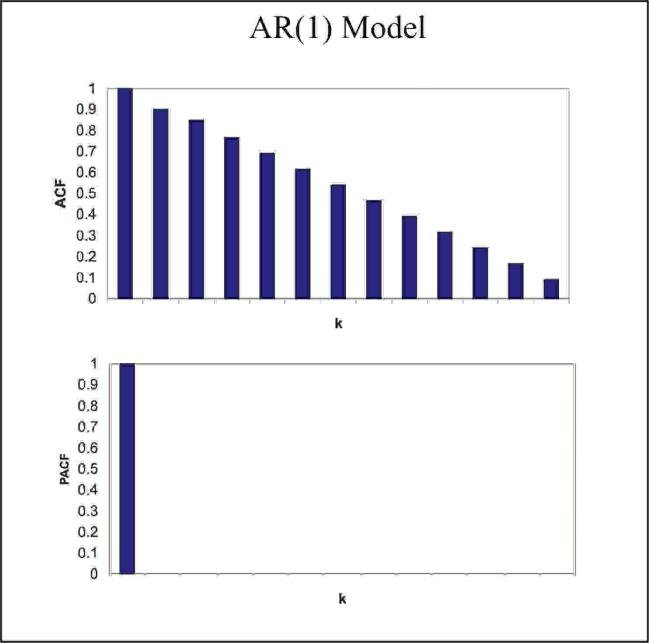

The big difference is in the ACF, which should go down exponencially; 
This indicates that the best starting point for the value of lags for the y should be 1. To further confirm this idea, we can try to train an AR model to this data, and see which value of p maximizes $R²$. 

## 4. Relation with the predictors

Correlations with the target at lags 0..k, to guide the exogenous lags q_k. This answers 4 big questions: 
1. Which variables have info about the output;
2. What's the best lag that has the most correlation?
3. Is there redundant variables?
4. Does it make physical sense? 

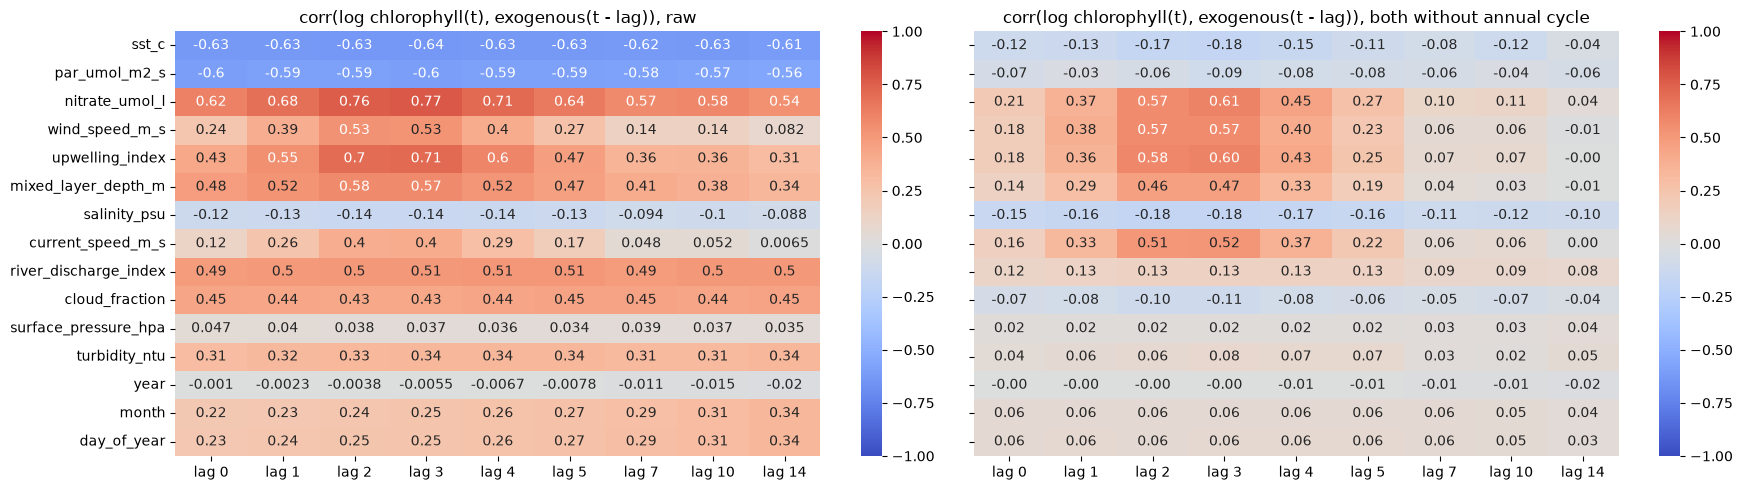

In [49]:
EXO_COLS = [c for c in raw.columns if c not in (DATE, TARGET)]
LAGS = [0, 1, 2, 3, 4, 5, 7, 10, 14]


# This function computes the residuals between the raw data and the seasonal data
def deseason(v, n_harmonics=2):
    Z = harmonic_design(raw[DATE].dt.dayofyear.to_numpy(), n_harmonics)
    coef, *_ = np.linalg.lstsq(Z, v, rcond=None)
    return v - Z @ coef


# Raw
target_raw = np.log(raw[TARGET].to_numpy())
corr_raw = pd.DataFrame(
    {
        c: [
            np.corrcoef(target_raw[l:], raw[c].to_numpy()[: len(raw) - l])[0, 1]
            for l in LAGS
        ]
        for c in EXO_COLS
    },
    index=[f"lag {l}" for l in LAGS],
).T

# Without annual cycle
target_deseason = deseason(np.log(raw[TARGET].to_numpy()))
corr_deseason = pd.DataFrame(
    {
        c: [
            np.corrcoef(
                target_deseason[l:],
                deseason(raw[c].to_numpy())[: len(raw) - l],
            )[0, 1]
            for l in LAGS
        ]
        for c in EXO_COLS
    },
    index=[f"lag {l}" for l in LAGS],
).T

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

sns.heatmap(corr_raw, annot = True, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("corr(log chlorophyll(t), exogenous(t - lag)), raw")

sns.heatmap(
    corr_deseason,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title(
    "corr(log chlorophyll(t), exogenous(t - lag)), both without annual cycle"
)

plt.tight_layout()
plt.show()

### Conclusions: 
1. SST has a big correlation when seasonality is considered, but after it drops to a maximum of -0.18 at lag 3;
2. PAR has a bigger decrease, going from a maximum of -0.6 to -0.09 at lag 0;
3. River discharge index had a big correlation, but it was purely seasonal;
4. day, month, year, surface_hpa, turbidity_ntu, cloud fraction had correlations in the order of ~0.3, but after getting the seasonality off, they dropped to almost 0
5. Nitrate decreases from 0.61 to 0.62 at lag 3;
6. Upwelling ("um fenômeno oceanográfico em que águas profundas, frias e muito ricas em nutrientes sobem para a camada superficial do oceano") has
a decrease from 0.71 to 0.6 at lag 3;
7. This picture gives a simple indication, the value of the lags that should be tested are: (Nitrate; 2, 3, 4, 5); (wind_speed; 2, 3, 4, 5) ...

This does not explain everything, it's important to check for colinearity between the features, and that can be analyzed trough the correation among them. 

<Axes: >

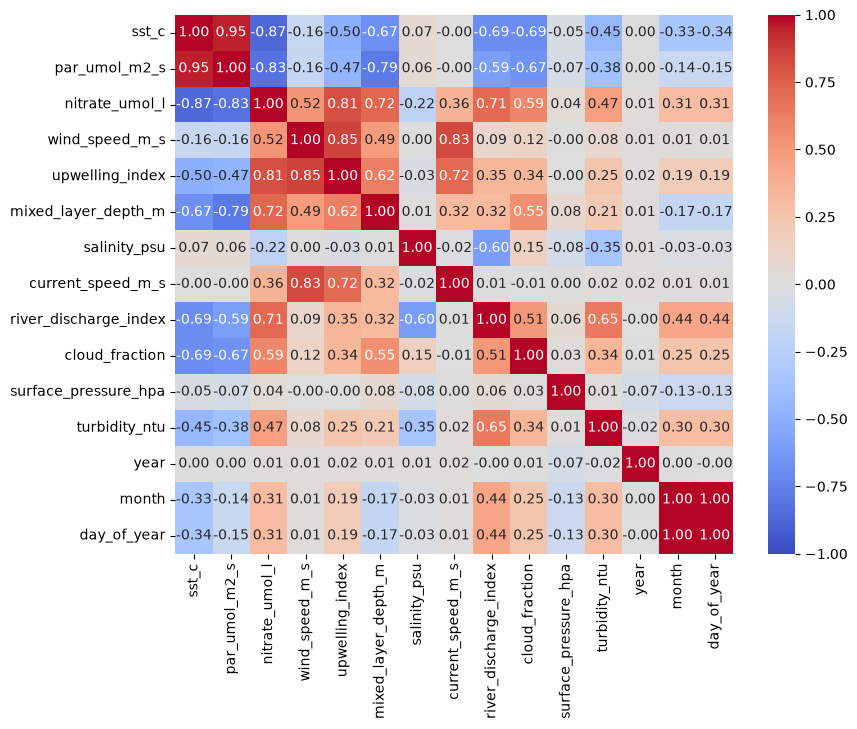

In [50]:
plt.figure(figsize=(9, 7))
sns.heatmap(raw[EXO_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)

### Conclusions: 
1. PAR and SST, Nitrate and SST, upwelling and wind, current and wind are strongly correlated. So wind has a high correlation but it's largely explained by upwelling). This makes the OLS coeficients have a huge variance, because the $(X^TX)^{-1}$ explodes when $X_T X$ is nearly singular. 